# 06 · Validation

Step 6 of the QSAR workflow, the parts the per-model notebooks leave out. All three read files
written by `scripts/validate.py`; nothing is refitted here.

1. **The comparison table** the proposal asks for, with every measure it names: AUC, MCC, log
   loss, Brier and calibration error.
2. **Y-randomization** — the check that the pipeline is not leaking.
3. **Cross-validation** — error bars, so a gap between two models can be called real or not.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"

metrics = pd.read_csv(PROC / "validation_metrics.csv")
yrand   = pd.read_csv(PROC / "validation_yrandomization.csv")
cv      = pd.read_csv(PROC / "validation_cv.csv")
baseline = pd.read_csv(PROC / "baseline_rf.csv")

ORDER = ["Model 1 logistic", "Model 2 censored", "Model 3 GP"]
COLOUR = {"Model 1 logistic": "#2a78d6", "Model 2 censored": "#d68a2a",
          "Model 3 GP": "#5a9e5a", "RF baseline": "#999999"}

## 1. The comparison table

One row per fitted model on its held-out test set. ARD and Gaussian priors differ by less than
0.01 everywhere, so only ARD is shown.

**ECE** (expected calibration error) is the mean gap between the probability a model announces
and the frequency it actually achieves. 0.02 means that when the model says 70%, the truth is
within about two points of that. It is the number that answers the proposal's question *are
the probabilities honest*; AUC cannot, because it only looks at ranking.

In [2]:
tab = (metrics[metrics["variant"].str.startswith(("ard", "tanimoto"))]
       .pivot_table(index="model", columns="split",
                    values=["AUC", "MCC", "log loss", "ECE"])
       .reindex(ORDER))
tab.round(3)

AUC                            ECE                \
split            cluster   hard random scaffold cluster   hard random   
model                                                                   
Model 1 logistic   0.846    NaN  0.868      NaN   0.028    NaN  0.028   
Model 2 censored   0.836    NaN  0.849      NaN   0.051    NaN  0.049   
Model 3 GP         0.865  0.858  0.879    0.873   0.058  0.056  0.072   

                              MCC                       log loss         \
split            scaffold cluster  hard random scaffold  cluster   hard   
model                                                                     
Model 1 logistic      NaN   0.529   NaN  0.577      NaN    0.485    NaN   
Model 2 censored      NaN   0.496   NaN  0.514      NaN    0.504    NaN   
Model 3 GP          0.077   0.565  0.54  0.595    0.586    0.468  0.482   

                                  
split            random scaffold  
model                             
Model 1 logistic  0.455      NaN  
Model 2 censored  0.490      NaN  
Model 3 GP        0.455    0.465

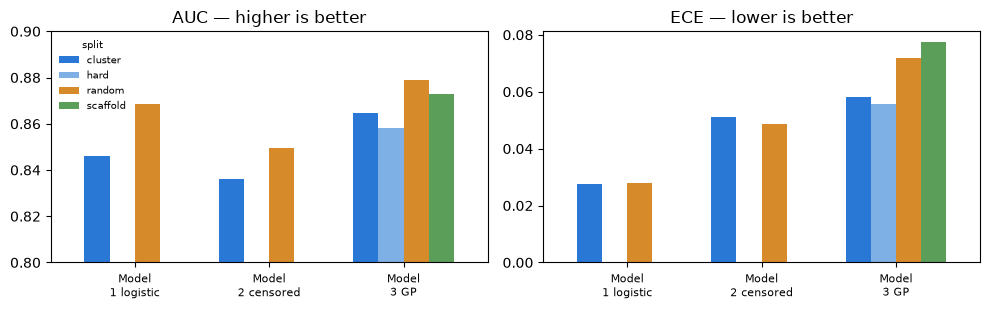

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (col, better) in zip(axes, [("AUC", "higher is better"), ("ECE", "lower is better")]):
    sub = metrics[metrics["variant"].str.startswith(("ard", "tanimoto"))]
    sub = sub.pivot_table(index="model", columns="split", values=col).reindex(ORDER)
    sub.plot.bar(ax=ax, width=0.75, legend=(col == "AUC"),
                 color=["#2a78d6", "#7fb0e5", "#d68a2a", "#5a9e5a"])
    ax.set_title(f"{col} — {better}"); ax.set_xlabel("")
    ax.set_xticklabels([t.get_text().replace(" ", "\n", 1) for t in ax.get_xticklabels()],
                       rotation=0, fontsize=8)
    if col == "AUC":
        ax.set_ylim(0.8, 0.9); ax.legend(title="split", fontsize=7, title_fontsize=7, frameon=False)
plt.tight_layout(); plt.show()

### What the table says

**The best-ranking model is the worst-calibrated one.** Model 3 wins on AUC and loses on ECE,
by a factor of three. The Laplace approximation for GP classification is known to understate
the magnitude of the latent function, and this is that showing up as a number: the GP's
probabilities are too close to 0.5 to be taken at face value.

That matters here more than the AUC does. The proposal's goal is a *calibrated* probability a
chemist can act on — "a 70% chance this flies" has to mean 70%. On that test Model 1 wins and
Model 3 comes last, which is the reverse of the AUC ranking.

## 2. Y-randomization

Shuffle the training labels, refit, score against the real test labels, 25 times per split. A
model that scores well on scrambled labels is reading something other than chemistry.

The shuffled AUCs scatter widely (sd ≈ 0.09) because 50 free coefficients fitted to noise can
land on a direction that happens to correlate with the truth. That is exactly why the check is
worth running: the spread, not just the mean, is what the real score has to clear.

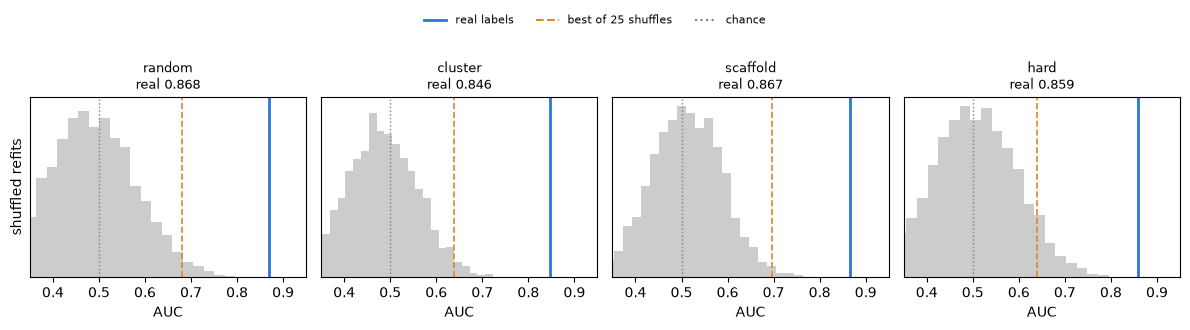

,split,real AUC,shuffled mean,shuffled sd,shuffled max,z,reps
0,random,0.868,0.485,0.095,0.680,4.019,25
1,cluster,0.846,0.479,0.078,0.638,4.726,25
2,scaffold,0.867,0.507,0.080,0.697,4.499,25
3,hard,0.859,0.502,0.094,0.639,3.792,25


In [4]:
fig, axes = plt.subplots(1, len(yrand), figsize=(3.0 * len(yrand), 2.9), sharey=True)
rng = np.random.default_rng(0)
for ax, (_, r) in zip(np.atleast_1d(axes), yrand.iterrows()):
    draws = rng.normal(r["shuffled mean"], r["shuffled sd"], 4000)
    ax.hist(draws, bins=30, color="#cccccc", edgecolor="none")
    ax.axvline(0.5, color="0.5", ls=":", lw=1)
    ax.axvline(r["shuffled max"], color="#d68a2a", ls="--", lw=1.2)
    ax.axvline(r["real AUC"], color="#2a78d6", lw=2)
    ax.set_title(f"{r['split']}\nreal {r['real AUC']:.3f}", fontsize=9)
    ax.set_xlim(0.35, 0.95); ax.set_yticks([]); ax.set_xlabel("AUC")
axes[0].set_ylabel("shuffled refits")
fig.legend(handles=[plt.Line2D([], [], color="#2a78d6", lw=2, label="real labels"),
                    plt.Line2D([], [], color="#d68a2a", ls="--", label="best of 25 shuffles"),
                    plt.Line2D([], [], color="0.5", ls=":", label="chance")],
           loc="upper center", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, 1.14))
plt.tight_layout(); plt.show()

yrand.round(3)

**Passed.** On every split the shuffled fits average about 0.49 — chance — and the luckiest of
25 reaches 0.70 at most, while the real model scores 0.85–0.87. The gap is four to five
standard deviations. Whatever the model has learnt, it is in the labels, not in the plumbing.

## 3. Cross-validation

Five folds inside each training set, with whole scaffolds and clusters kept together, so a fold
is as honest as the outer test set. This is the only place in the project that produces a
spread rather than a single number, and the spread is what decides whether a gap is real.

Model 3 is absent on purpose: one GP fit takes about eight minutes, so twenty of them would
cost hours to answer a question the two fast models already answer.

In [5]:
agg = (cv.groupby(["split", "model"])[["AUC", "MCC", "log loss", "ECE"]]
         .agg(["mean", "std"]).round(3))
agg

AUC           MCC        log loss           ECE  \
                            mean    std   mean    std     mean    std   mean   
split    model                                                                 
cluster  Model 1 logistic  0.865  0.006  0.563  0.012    0.459  0.013  0.027   
         Model 2 censored  0.852  0.009  0.533  0.020    0.483  0.015  0.044   
         RF baseline       0.847  0.006  0.533  0.015    0.488  0.006  0.041   
hard     Model 1 logistic  0.861  0.010  0.557  0.018    0.462  0.014  0.025   
         Model 2 censored  0.850  0.014  0.531  0.032    0.482  0.012  0.042   
         RF baseline       0.848  0.012  0.530  0.016    0.485  0.012  0.041   
random   Model 1 logistic  0.860  0.010  0.549  0.014    0.465  0.018  0.026   
         Model 2 censored  0.848  0.011  0.521  0.022    0.489  0.016  0.046   
         RF baseline       0.848  0.007  0.540  0.010    0.488  0.009  0.040   
scaffold Model 1 logistic  0.858  0.011  0.556  0.015    0.469  0.013  0.023   
         Model 2 censored  0.846  0.011  0.518  0.018    0.492  0.014  0.050   
         RF baseline       0.849  0.012  0.543  0.017    0.488  0.012  0.052   

                                  
                             std  
split    model                    
cluster  Model 1 logistic  0.005  
         Model 2 censored  0.007  
         RF baseline       0.012  
hard     Model 1 logistic  0.005  
         Model 2 censored  0.007  
         RF baseline       0.009  
random   Model 1 logistic  0.009  
         Model 2 censored  0.011  
         RF baseline       0.005  
scaffold Model 1 logistic  0.005  
         Model 2 censored  0.008  
         RF baseline       0.010

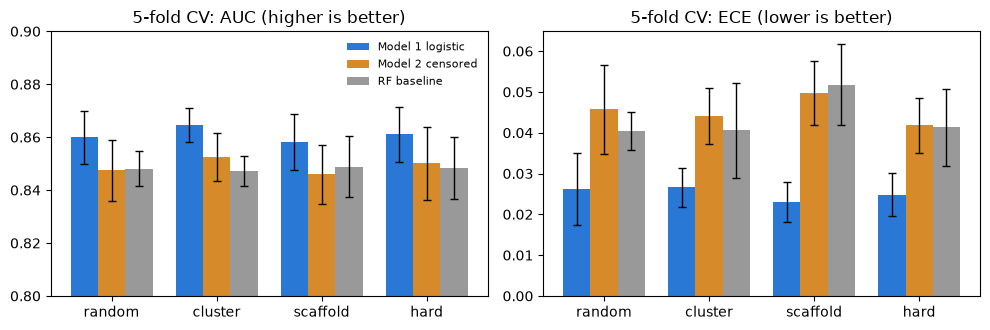

In [6]:
models = ["Model 1 logistic", "Model 2 censored", "RF baseline"]
splits = list(cv["split"].unique())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

for ax, col, better in [(axes[0], "AUC", "higher"), (axes[1], "ECE", "lower")]:
    w = 0.26
    for j, m in enumerate(models):
        sub = cv[cv["model"] == m].groupby("split")[col].agg(["mean", "std"]).reindex(splits)
        ax.bar(np.arange(len(splits)) + (j - 1) * w, sub["mean"], w, yerr=sub["std"],
               capsize=3, color=COLOUR[m], label=m, error_kw={"lw": 1})
    ax.set_xticks(range(len(splits))); ax.set_xticklabels(splits)
    ax.set_title(f"5-fold CV: {col} ({better} is better)")
    if col == "AUC":
        ax.set_ylim(0.80, 0.90); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

In [7]:
# Is Model 1's lead bigger than fold-to-fold noise? Paired per fold, which removes the
# fold-difficulty that both models share.
pairs = cv.pivot_table(index=["split", "fold"], columns="model", values=["AUC", "ECE"])
for col in ["AUC", "ECE"]:
    d = pairs[col]["Model 1 logistic"] - pairs[col]["RF baseline"]
    direction = "higher" if col == "AUC" else "lower"
    print(f"{col}: Model 1 minus RF = {d.mean():+.3f} +- {d.std():.3f} "
          f"over {len(d)} folds | {direction} in {(d > 0).sum() if col == 'AUC' else (d < 0).sum()}/{len(d)}")

AUC: Model 1 minus RF = +0.013 +- 0.006 over 20 folds | higher in 20/20
ECE: Model 1 minus RF = -0.018 +- 0.012 over 20 folds | lower in 19/20


### What cross-validation settles

**Model 1's lead over the forest is real.** Pairing fold by fold — which cancels the
difficulty each fold shares between the two models — Model 1 has the higher AUC in 20 folds out
of 20 (+0.013 ± 0.006) and the lower calibration error in 19 of 20 (−0.018 ± 0.012). The AUC
margin is small, but a 20-for-20 sweep is not luck.

The calibration margin is the larger one in proportion: roughly half the error, consistently.
So the honest summary is not "the Bayesian model predicts much better". It is: *it predicts a
little better and it knows what it knows*. For a screen deciding which compounds to run, the
second property is the one worth having.

**The four splits agree.** Random, cluster, scaffold and hard land within 0.01 AUC of each
other. That is a statement about the library rather than the models: with 7,067 clusters among
11,353 compounds and most of them singletons, holding out "new chemistry" is barely harder than
holding out at random. A model trained here should be expected to generalise — but that also
means this dataset cannot demonstrate an applicability domain, because it has no genuinely
out-of-domain corner to fail on.